data=
    population   profit
0      6.1101  17.5920
1      5.5277   9.1302
2      8.5186  13.6620
3      7.0032  11.8540
4      5.8598   6.8233
5      8.3829  11.8860
6      7.4764   4.3483
7      8.5781  12.0000
8      6.4862   6.5987
9      5.0546   3.8166
*********************
data.describe=
        population     profit
count   97.000000  97.000000
mean     8.159800   5.839135
std      3.869884   5.510262
min      5.026900  -2.680700
25%      5.707700   1.986900
50%      6.589400   4.562300
75%      8.578100   7.046700
max     22.203000  24.147000
*********************
Initial Cost: 32.072733877455676
*********************
Final Theta (g):
 [[-3.24140214  1.1272942 ]]
Final Cost: 4.515955503078914
*********************


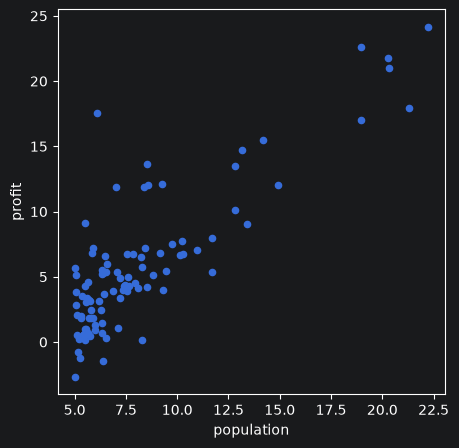

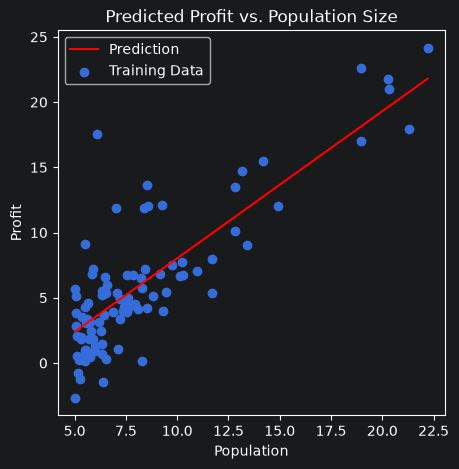

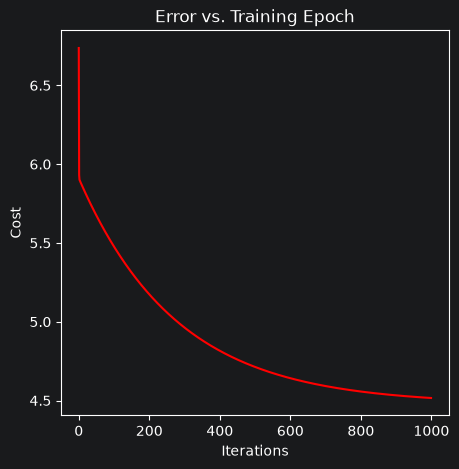

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

path = r"C:\Users\(Victor)\Downloads\ML.csv"
data = pd.read_csv(path, header=None, names=['population', 'profit'])

print('data=\n', data.head(10))
print("*********************")
print('data.describe=\n', data.describe())
print("*********************")

data.plot(kind='scatter', x='population', y='profit', figsize=(5, 5))

data.insert(0, 'ones', 1)
cols = data.shape[1]
X = data.iloc[:, 0:cols-1]
y = data.iloc[:, cols-1:cols]

X = np.matrix(X.values)
y = np.matrix(y.values)
thetaa = np.matrix(np.array([0, 0]))

def computeCost(X, y, theta):
    z = np.power(((X * theta.T) - y), 2)
    return np.sum(z) / (2 * len(X))

print('Initial Cost:', computeCost(X, y, thetaa))
print("*********************")

def gradientDescent(X, y, thetaa, alpha, iters):
    temp = np.matrix(np.zeros(thetaa.shape))
    parameters = int(thetaa.ravel().shape[1])
    cost = np.zeros(iters)

    for i in range(iters):
        error = (X * thetaa.T) - y
        for j in range(parameters):
            term = np.multiply(error, X[:, j])
            temp[0, j] = thetaa[0, j] - ((alpha / len(X)) * np.sum(term))
        thetaa = temp
        cost[i] = computeCost(X, y, thetaa)

    return thetaa, cost

alpha = 0.01
iters = 1000

g, cost = gradientDescent(X, y, thetaa, alpha, iters)
print('Final Theta (g):\n', g)
print('Final Cost:', computeCost(X, y, g))
print("*********************")

# رسم خط التوقع (Best Fit Line)
x = np.linspace(data.population.min(), data.population.max(), 100)
f = g[0, 0] + (g[0, 1] * x)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(x, f, 'r', label='Prediction')
ax.scatter(data.population, data.profit, label='Training Data')
ax.legend(loc=2)
ax.set_xlabel('Population')
ax.set_ylabel('Profit')
ax.set_title('Predicted Profit vs. Population Size')

# رسم منحنى تعلم الخوارزمية (Cost vs Iterations)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(np.arange(iters), cost, 'r')
ax.set_xlabel('Iterations')
ax.set_ylabel('Cost')
ax.set_title('Error vs. Training Epoch')

plt.show()